# Do AI face detectors learn fakes, or shortcuts?

This notebook reproduces the project's main findings at small scale, from public data only,
in one run. It downloads about 3 GB, embeds every image once with a frozen CLIP ViT-L/14,
and trains small linear classifiers on those embeddings.

It asks four questions:

1. How well does a detector do on the same kind of fakes and reals it was trained on?
2. Does it still catch fakes from a generator it never saw?
3. Does it flag real faces from other datasets as fake?
4. Does training on reals from more than one dataset fix that?

The short answer: the scores look perfect, and the detector has largely learned which
dataset an image comes from. That is the main lesson of the full project (see the README),
whose models were fine-tuned on far more data; the numbers here are smaller-scale.

**Running it.** Python 3.10 or newer and about 4 GB of free disk. The slow step is
downloading and embedding 7,724 images: about 15 minutes on a laptop RTX 4050 (Google
Colab's free T4 is similar), and 1.5 to 2 hours on a CPU. On Colab, choose a GPU runtime
and run all cells; elsewhere, `pip install -r requirements.txt` from the repository root.
If `features_clip_l14.npz` sits next to the notebook and was made with the same settings
(the committed copy was), the embedding step is skipped and the whole notebook runs in
about a minute on a CPU, with no download.

## Data

| Source | Content | Images used | License |
|---|---|---:|---|
| [SFHQ-T2I](https://huggingface.co/datasets/bitmind/SyntheticFacesHighQuality-T2I), small sample | AI-generated faces: FLUX.1-dev 859, FLUX.1-pro 315, SDXL 550 (JPEG, quality 90) | all 1,724 | MIT (upstream SFHQ) |
| [FFHQ](https://huggingface.co/datasets/gaunernst/ffhq-1024-wds), shards 35000 and 50000 | Real Flickr portraits (lossless WebP) | 2,000 | CC BY-NC-SA 4.0 |
| [FairFace](https://huggingface.co/datasets/HuggingFaceM4/FairFace), first training shard | Real face crops balanced by age, gender and race; adults only | 1,000 | CC BY 4.0 |
| [LFW](https://huggingface.co/datasets/bitmind/lfw) | Real news photos of public figures; one per person | 1,000 | not stated on the dataset card |

Every download is pinned to a fixed dataset revision, and every random choice uses one seed.

In [1]:
# On Colab every package below is preinstalled except possibly a recent huggingface_hub.
# Elsewhere: pip install torch "transformers>=4.56" huggingface_hub pyarrow scikit-learn matplotlib pandas pillow
import io
import json
import os
import platform
import re
import tarfile
import time
import zipfile
import zlib
from pathlib import Path

import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import sklearn
import torch
import transformers
from huggingface_hub import hf_hub_download
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import CLIPImageProcessor, CLIPModel

STARTED = time.time()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VERSIONS = {"python": platform.python_version(), "torch": torch.__version__,
            "transformers": transformers.__version__, "scikit-learn": sklearn.__version__,
            "numpy": np.__version__, "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"}
VERSIONS

{'python': '3.12.5',
 'torch': '2.11.0+cu128',
 'transformers': '5.22.2',
 'scikit-learn': '1.9.1',
 'numpy': '2.5.4',
 'device': 'NVIDIA GeForce RTX 4050 Laptop GPU'}

In [2]:
SEED = 20261113
DATA_DIR = Path(os.environ.get("NOTEBOOK_DATA", "data_notebook"))   # downloads go here
FEATURES = Path(os.environ.get("NOTEBOOK_FEATURES", "features_clip_l14.npz"))
FIGURES = Path("figures")
N_FAIRFACE = 1000
N_LFW = 1000
TARGET_FPR = 0.05          # share of validation reals the locked threshold may flag
SPLIT = (0.5, 0.2, 0.3)    # train, validation, test

CLIP = ("openai/clip-vit-large-patch14", "32bd64288804d66eefd0ccbe215aa642df71cc41")
SOURCES = {
    "sfhq": ("bitmind/SyntheticFacesHighQuality-T2I", "c7f422bdcaf4ffe1ced6da49198845c874221a03",
             ["small-sample.zip"]),
    "ffhq": ("gaunernst/ffhq-1024-wds", "d74f1f1f59e3bbe975bee29872b9bef827314577",
             ["35000.tar", "50000.tar"]),
    "fairface": ("HuggingFaceM4/FairFace", "54d573cdb8b5af490ba8da9da2799628f6e5c496",
                 ["1.25/train-00000-of-00004-e715178553977907.parquet"]),
    "lfw": ("bitmind/lfw", "274dfbca8b2dc9c6d21ae80f8627c911222eb347",
            ["data/train-00000-of-00001.parquet"]),
}
SETTINGS = {"seed": SEED, "n_fairface": N_FAIRFACE, "n_lfw": N_LFW, "clip": CLIP,
            "sources": {name: source[:2] for name, source in SOURCES.items()}}

## Download and read the images

In [3]:
def fetch(name):
    # Download one source's files at its pinned revision; files already on disk are reused.
    repository, revision, files = SOURCES[name]
    paths = []
    for filename in files:
        path = DATA_DIR / name / filename
        if not path.is_file():
            hf_hub_download(repository, filename, repo_type="dataset", revision=revision,
                            local_dir=DATA_DIR / name)
        paths.append(path)
    return paths


def sample(rows, n, label):
    rng = np.random.default_rng([SEED, zlib.crc32(label.encode())])
    keep = rng.choice(len(rows), size=min(n, len(rows)), replace=False)
    return [rows[i] for i in sorted(keep)]


GENERATORS = {"FLUX1_dev": "FLUX.1-dev", "FLUX1_pro": "FLUX.1-pro", "SDXL": "SDXL"}
FAIRFACE_ADULT = 3   # FairFace age classes 0, 1 and 2 are under 20


def read_sfhq():
    (path,) = fetch("sfhq")
    with zipfile.ZipFile(path) as archive:
        for name in sorted(archive.namelist()):
            match = re.fullmatch(r"(.+)_image_\d+\.jpg", Path(name).name)
            if match:
                yield (dict(image=f"sfhq/{name}", source="SFHQ-T2I",
                            generator=GENERATORS[match[1]], label=1), archive.read(name))


def read_ffhq():
    for path in fetch("ffhq"):
        with tarfile.open(path) as archive:
            for member in archive:
                if member.isfile() and member.name.endswith(".webp"):
                    yield (dict(image=f"ffhq/{member.name}", source="FFHQ", generator="real",
                                label=0), archive.extractfile(member).read())


def read_fairface():
    (path,) = fetch("fairface")
    rows = [row for row in pq.read_table(path, columns=["image", "age"]).to_pylist()
            if row["age"] >= FAIRFACE_ADULT]
    for index, row in enumerate(sample(rows, N_FAIRFACE, "fairface")):
        yield (dict(image=f"fairface/{index:04d}", source="FairFace", generator="real", label=0),
               row["image"]["bytes"])


def read_lfw():
    (path,) = fetch("lfw")
    first = {}
    for row in sorted(pq.read_table(path).to_pylist(), key=lambda row: row["filename"]):
        first.setdefault(re.sub(r"_\d+\.\w+$", "", row["filename"]), row)
    for row in sample(list(first.values()), N_LFW, "lfw"):
        yield (dict(image=f"lfw/{row['filename']}", source="LFW", generator="real", label=0),
               row["image"]["bytes"])


def as_jpeg(image, quality=90):
    # Re-save a real image the way the SFHQ fakes are stored: JPEG, quality 90, 4:2:0 chroma.
    buffer = io.BytesIO()
    image.save(buffer, "JPEG", quality=quality, subsampling=2)
    buffer.seek(0)
    return Image.open(buffer).convert("RGB")


def all_images():
    for reader in (read_sfhq, read_ffhq, read_fairface, read_lfw):
        for record, data in reader():
            image = Image.open(io.BytesIO(data)).convert("RGB")
            yield {**record, "variant": "original"}, image
            if record["source"] == "FFHQ":
                yield {**record, "variant": "jpeg90"}, as_jpeg(image)

## Embed every image once

Each image is resized and center-cropped to 224 px by CLIP's own preprocessing and turned into
one 768-number embedding. Nothing in CLIP is trained here.

In [4]:
def embed_all(batch_size=32):
    processor = CLIPImageProcessor.from_pretrained(CLIP[0], revision=CLIP[1])
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    model = CLIPModel.from_pretrained(CLIP[0], revision=CLIP[1], dtype=dtype).to(DEVICE).eval()
    records, chunks, batch = [], [], []

    def flush():
        pixels = processor(images=[image for _, image in batch], return_tensors="pt")["pixel_values"]
        with torch.inference_mode():
            vectors = model.get_image_features(pixel_values=pixels.to(DEVICE, dtype))
        if not isinstance(vectors, torch.Tensor):   # newer transformers return an output object
            vectors = vectors.image_embeds if getattr(vectors, "image_embeds", None) is not None \
                else vectors.pooler_output
        chunks.append(torch.nn.functional.normalize(vectors.float(), dim=-1).cpu().numpy())
        records.extend(record for record, _ in batch)
        batch.clear()

    for item in all_images():
        batch.append(item)
        if len(batch) == batch_size:
            flush()
    if batch:
        flush()
    return pd.DataFrame(records), np.concatenate(chunks)


cached = np.load(FEATURES, allow_pickle=False) if FEATURES.is_file() else None
if cached is not None and json.loads(str(cached["settings"])) == json.loads(json.dumps(SETTINGS)):
    meta = pd.DataFrame(json.loads(str(cached["meta"])))
    X = cached["features"].astype(np.float32)
    print(f"Loaded {len(meta):,} embeddings from {FEATURES}")
else:
    begin = time.time()
    meta, X = embed_all()
    np.savez_compressed(FEATURES, features=X.astype(np.float16),
                        meta=json.dumps(meta.to_dict("list")), settings=json.dumps(SETTINGS))
    X = X.astype(np.float16).astype(np.float32)   # same precision as a cached run
    print(f"Embedded {len(meta):,} images in {time.time() - begin:.0f} s on {DEVICE}")

y = meta["label"].to_numpy()
meta.groupby(["source", "generator", "variant"]).size().rename("images").to_frame()

Loaded 7,724 embeddings from features_clip_l14.npz


images
source   generator  variant         
FFHQ     real       jpeg90      2000
                    original    2000
FairFace real       original    1000
LFW      real       original    1000
SFHQ-T2I FLUX.1-dev original     859
         FLUX.1-pro original     315
         SDXL       original     550

## Splits and the detector

Every source and generator is split on its own into train (50%), validation (20%) and test
(30%). The JPEG copy of an FFHQ image always lands in the same split as the original.

The detector is a logistic regression on the CLIP embedding. Its regularization strength is
picked on validation data. Its decision threshold is then locked on validation reals so that
5% of them are flagged as fake, and it is never changed after that: test data is only scored.

In [5]:
def assign_splits(meta):
    rng = np.random.default_rng(SEED)
    split = {}
    originals = meta[meta["variant"] == "original"]
    for _, group in originals.groupby(["source", "generator"], sort=True):
        images = group["image"].to_numpy()
        n_train, n_val = round(len(images) * SPLIT[0]), round(len(images) * SPLIT[1])
        for rank, index in enumerate(rng.permutation(len(images))):
            split[images[index]] = ("train" if rank < n_train
                                    else "val" if rank < n_train + n_val else "test")
    return meta["image"].map(split).to_numpy()


meta["split"] = assign_splits(meta)


def subset(split, fakes=(), reals=()):
    # Rows of one split: fakes from the named generators plus reals from (source, variant) pairs.
    rows = meta["split"].to_numpy() == split
    fake = (meta["label"].eq(1) & meta["generator"].isin(fakes)).to_numpy()
    real = np.zeros(len(meta), dtype=bool)
    for source, variant in reals:
        real |= (meta["source"].eq(source) & meta["variant"].eq(variant)).to_numpy()
    return rows & (fake | real)


class Detector:
    def __init__(self, fakes, reals):
        train, val = subset("train", fakes, reals), subset("val", fakes, reals)
        best = None
        for c in (0.01, 0.1, 1.0, 10.0):
            model = make_pipeline(StandardScaler(), LogisticRegression(
                C=c, class_weight="balanced", max_iter=5000)).fit(X[train], y[train])
            auroc = roc_auc_score(y[val], model.decision_function(X[val]))
            if best is None or auroc > best[0]:
                best = (auroc, c, model)
        self.validation_auroc, self.c, self.model = best
        self.threshold = np.quantile(self.score(val & (y == 0)), 1 - TARGET_FPR)

    def score(self, rows):
        return self.model.decision_function(X[rows])

    def flagged(self, rows):
        return float(np.mean(self.score(rows) > self.threshold))


def auroc_interval(fake_scores, real_scores, reps=1000):
    # AUROC with a 95% bootstrap interval, resampling fakes and reals separately.
    rng = np.random.default_rng(SEED)
    labels = np.r_[np.ones(len(fake_scores)), np.zeros(len(real_scores))]
    point = roc_auc_score(labels, np.r_[fake_scores, real_scores])
    draws = [roc_auc_score(labels, np.r_[rng.choice(fake_scores, len(fake_scores)),
                                         rng.choice(real_scores, len(real_scores))])
             for _ in range(reps)]
    low, high = np.percentile(draws, [2.5, 97.5])
    return round(point, 3), [round(low, 3), round(high, 3)]


def evaluate(detector, fakes, reals):
    fake_rows, real_rows = subset("test", fakes=fakes), subset("test", reals=reals)
    auroc, interval = auroc_interval(detector.score(fake_rows), detector.score(real_rows))
    caught, flagged = detector.flagged(fake_rows), detector.flagged(real_rows)
    return {"auroc": auroc, "auroc_95": interval, "fakes_caught": round(caught, 3),
            "reals_flagged": round(flagged, 3),
            "balanced_accuracy": round((caught + 1 - flagged) / 2, 3),
            "test_fakes": int(fake_rows.sum()), "test_reals": int(real_rows.sum())}


ALL = ["SDXL", "FLUX.1-dev", "FLUX.1-pro"]
FFHQ = [("FFHQ", "original")]
RESULTS = {}

## 1. The easy score

Train on all three generators against FFHQ reals; test on held-out images from the same
sources. This is the setting most published detectors report.

In [6]:
easy = Detector(ALL, FFHQ)
RESULTS["1_same_sources"] = evaluate(easy, ALL, FFHQ)
RESULTS["1_same_sources"]

{'auroc': 1.0,
 'auroc_95': [np.float64(1.0), np.float64(1.0)],
 'fakes_caught': 1.0,
 'reals_flagged': 0.033,
 'balanced_accuracy': 0.983,
 'test_fakes': 516,
 'test_reals': 600}

## 2. A generator the detector never saw

Train on SDXL fakes only, then test on SDXL, FLUX.1-dev and FLUX.1-pro fakes against the same
held-out FFHQ reals. (The plotting helpers used later are defined here too.)

In [7]:
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
matplotlib.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "legend.frameon": False})
FIGURES.mkdir(exist_ok=True)


def percent_bars(groups, series, title, path, reference):
    # Grouped bars of shares, labelled in percent, with a dashed reference line.
    fig, ax = plt.subplots(figsize=(8, 4.4))
    width = 0.8 / len(series)
    top = max(max(values) for values in series.values())
    for k, ((label, values), color) in enumerate(zip(series.items(), (BLUE, ORANGE))):
        positions = np.arange(len(groups)) + (k - (len(series) - 1) / 2) * width
        ax.bar(positions, values, width * 0.94, color=color, label=label,
               edgecolor=SURFACE, linewidth=2)
        for x, value in zip(positions, values):
            ax.text(x, value + top * 0.02, f"{value:.1%}", ha="center", va="bottom",
                    fontsize=10, color=INK_2, zorder=4,
                    bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.axhline(reference, color=INK_2, linewidth=1, linestyle=(0, (4, 3)), zorder=1.5,
               label=f"{reference:.0%} target")
    ax.set_xticks(np.arange(len(groups)), groups)
    ax.set_ylim(0, top * 1.25)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=34)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=len(series) + 1, fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()


def score_panels(panels, threshold, title, path):
    # One histogram per group of test images on a shared score axis.
    scores = np.concatenate([s for _, s, _ in panels])
    bins = np.linspace(np.percentile(scores, 0.5), np.percentile(scores, 99.5), 50)
    fig, axes = plt.subplots(len(panels), 1, figsize=(8, 1.35 * len(panels) + 0.8),
                             sharex=True)
    for ax, (label, values, color) in zip(axes, panels):
        ax.hist(np.clip(values, bins[0], bins[-1]), bins=bins, color=color,
                edgecolor=SURFACE, linewidth=0.6)
        ax.axvline(threshold, color=INK_2, linewidth=1, linestyle=(0, (4, 3)))
        flagged = np.mean(values > threshold)
        ax.set_title(f"{label}: {flagged:.1%} called fake", loc="left", fontsize=10,
                     color=INK)
        ax.set_yticks([])
        ax.grid(False)
    axes[0].text(threshold, axes[0].get_ylim()[1], " locked threshold", va="top",
                 fontsize=9, color=INK_2)
    axes[-1].set_xlabel("Detector score (higher means more likely fake)")
    fig.suptitle(title, x=0.02, ha="left", fontsize=12, color=INK)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()


sdxl_only = Detector(["SDXL"], FFHQ)
RESULTS["2_unseen_generator"] = {g: evaluate(sdxl_only, [g], FFHQ) for g in ALL}
pd.DataFrame(RESULTS["2_unseen_generator"]).T

,auroc,auroc_95,fakes_caught,reals_flagged,balanced_accuracy,test_fakes,test_reals
SDXL,1.0,"[1.0, 1.0]",1.0,0.037,0.982,165,600
FLUX.1-dev,1.0,"[0.999, 1.0]",1.0,0.037,0.982,257,600
FLUX.1-pro,1.0,"[0.999, 1.0]",1.0,0.037,0.982,94,600


The FLUX models are caught as well as SDXL. That looks like generalization, but all three
generators come from one dataset, SFHQ-T2I, made with one pipeline (same prompts, crops and
JPEG settings), and all reals come from FFHQ. A detector can separate the two datasets
without learning anything about generators, so this test cannot tell the two apart. The
full project's FLUX results, on fakes and reals from other pipelines, are far lower (README,
Section 3.7). Sections 3 and 4 test the dataset explanation directly.

## 3. Real faces from other datasets

The detector from section 1 saw only FFHQ reals. Here it scores real faces it never saw: FFHQ
images re-saved as JPEG (the format of the fakes), FairFace and LFW. A detector that had learned
what makes a face fake would flag about 5% of each, the rate its threshold was set to.

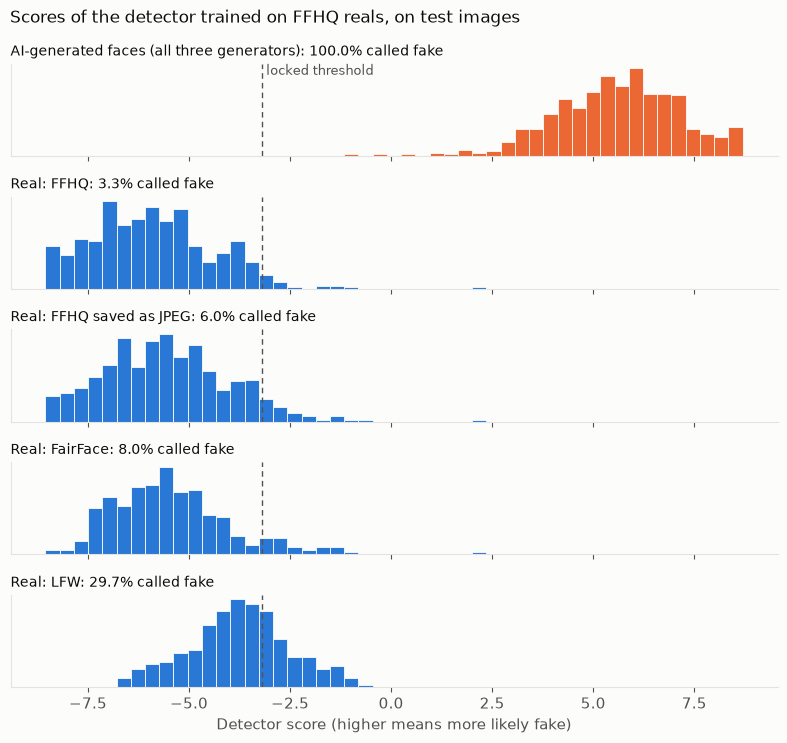

,share of reals flagged as fake
FFHQ,0.033
FFHQ saved as JPEG,0.060
FairFace,0.080
LFW,0.297


In [8]:
REAL_SETS = {"FFHQ": ("FFHQ", "original"), "FFHQ saved as JPEG": ("FFHQ", "jpeg90"),
             "FairFace": ("FairFace", "original"), "LFW": ("LFW", "original")}
RESULTS["3_reals_flagged"] = {name: round(easy.flagged(subset("test", reals=[pair])), 3)
                              for name, pair in REAL_SETS.items()}
score_panels([("AI-generated faces (all three generators)", easy.score(subset("test", ALL)), ORANGE),
              *[(f"Real: {name}", easy.score(subset("test", reals=[pair])), BLUE)
                for name, pair in REAL_SETS.items()]],
             easy.threshold, "Scores of the detector trained on FFHQ reals, on test images",
             FIGURES / "score_by_source.png")
pd.Series(RESULTS["3_reals_flagged"], name="share of reals flagged as fake").to_frame()

Every real dataset the detector did not train on is flagged more often than the 5% target,
and LFW news photos far more often. Can the embeddings tell the real datasets apart, with no
fakes involved? If they can, a detector trained on one of them can learn "looks like FFHQ"
instead of "looks real".

In [9]:
def source_auroc(a, b):
    pairs = [(a, "original"), (b, "original")]
    train, test = subset("train", reals=pairs), subset("test", reals=pairs)
    is_b = meta["source"].eq(b).to_numpy()
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))
    model.fit(X[train], is_b[train])
    return round(roc_auc_score(is_b[test], model.decision_function(X[test])), 3)


RESULTS["3_real_source_auroc"] = {f"{a} vs {b}": source_auroc(a, b) for a, b in
                                  [("FFHQ", "FairFace"), ("FFHQ", "LFW"), ("FairFace", "LFW")]}
pd.Series(RESULTS["3_real_source_auroc"], name="AUROC, real vs real").to_frame()

,"AUROC, real vs real"
FFHQ vs FairFace,1.0
FFHQ vs LFW,1.0
FairFace vs LFW,1.0


## 4. Training on reals from more than one source

Two detectors with the same fakes (SDXL and FLUX.1-dev). The first sees FFHQ reals only; the
second also sees FairFace reals and JPEG copies of the FFHQ reals. Both are tested on LFW reals,
which neither has seen, and on FLUX.1-pro fakes, which neither has seen.

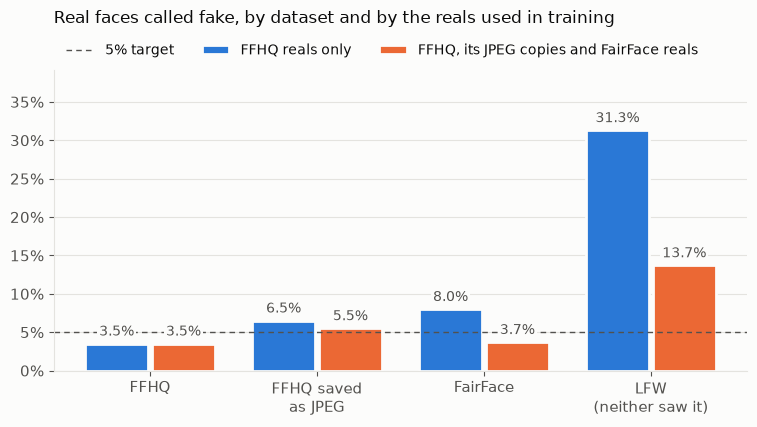

,Trained on FFHQ reals,"Trained on FFHQ, its JPEG copies and FairFace reals"
auroc,1.0,1.0
auroc_95,"[1.0, 1.0]","[1.0, 1.0]"
fakes_caught,1.0,1.0
reals_flagged,0.313,0.137
balanced_accuracy,0.843,0.932
test_fakes,94,94
test_reals,300,300


In [10]:
SEEN_FAKES = ["SDXL", "FLUX.1-dev"]
MIXED = [("FFHQ", "original"), ("FFHQ", "jpeg90"), ("FairFace", "original")]
detectors = {"Trained on FFHQ reals": Detector(SEEN_FAKES, FFHQ),
             "Trained on FFHQ, its JPEG copies and FairFace reals": Detector(SEEN_FAKES, MIXED)}
RESULTS["4_mixed_reals"] = {
    name: {"reals_flagged": {real: round(d.flagged(subset("test", reals=[pair])), 3)
                             for real, pair in REAL_SETS.items()},
           "flux_pro_vs_lfw": evaluate(d, ["FLUX.1-pro"], [("LFW", "original")])}
    for name, d in detectors.items()}
mixed = RESULTS["4_mixed_reals"]
percent_bars(["FFHQ", "FFHQ saved\nas JPEG", "FairFace", "LFW\n(neither saw it)"],
             {"FFHQ reals only": list(mixed["Trained on FFHQ reals"]["reals_flagged"].values()),
              "FFHQ, its JPEG copies and FairFace reals":
                  list(mixed["Trained on FFHQ, its JPEG copies and FairFace reals"]["reals_flagged"].values())},
             "Real faces called fake, by dataset and by the reals used in training",
             FIGURES / "real_sources.png", reference=TARGET_FPR)
pd.DataFrame({name: r["flux_pro_vs_lfw"] for name, r in mixed.items()})

Training on a second real dataset cuts the false alarms on LFW, which neither detector saw,
by more than half, but they stay well above the 5% target. More varied reals help; they do
not make the detector learn what a fake is. In the full project the same pattern needed
balanced real sources, matched file formats and much more training data (README,
Sections 3.5 to 3.7).

## Summary

In [11]:
same = RESULTS["1_same_sources"]
summary = pd.DataFrame([
    ["1. Same sources", "all three generators vs FFHQ", same["auroc"], same["balanced_accuracy"]],
    *[[f"2. Trained on SDXL, tested on {g}", f"{g} vs FFHQ", r["auroc"], r["balanced_accuracy"]]
      for g, r in RESULTS["2_unseen_generator"].items()],
    *[[f"4. {name}", "FLUX.1-pro vs LFW (both unseen)", r["flux_pro_vs_lfw"]["auroc"],
       r["flux_pro_vs_lfw"]["balanced_accuracy"]] for name, r in RESULTS["4_mixed_reals"].items()],
], columns=["Experiment", "Test pair", "AUROC", "Balanced accuracy"])
with open("results.json", "w", encoding="utf-8") as stream:
    json.dump({"results": RESULTS, "settings": SETTINGS, "versions": VERSIONS}, stream, indent=2)
print(f"Finished in {time.time() - STARTED:.0f} s")
summary

Finished in 15 s


,Experiment,Test pair,AUROC,Balanced accuracy
0,1. Same sources,all three generators vs FFHQ,1.0,0.983
1,"2. Trained on SDXL, tested on SDXL",SDXL vs FFHQ,1.0,0.982
2,"2. Trained on SDXL, tested on FLUX.1-dev",FLUX.1-dev vs FFHQ,1.0,0.982
3,"2. Trained on SDXL, tested on FLUX.1-pro",FLUX.1-pro vs FFHQ,1.0,0.982
4,4. Trained on FFHQ reals,FLUX.1-pro vs LFW (both unseen),1.0,0.843
5,"4. Trained on FFHQ, its JPEG copies and FairFa...",FLUX.1-pro vs LFW (both unseen),1.0,0.932
